# Checkpoint 3 — Clustering aplicado à energia

**Atividade prática em Python | K-Means, Elbow e Silhouette Score**

**Nome e RM:** Victor Vidigal — RM 571318

## Situação-problema

Uma equipe de gestão de energia quer conhecer os diferentes perfis de uso de suas unidades consumidoras para planejar ações de acompanhamento e uso consciente de energia. Cada registro reúne informações de uma unidade no mesmo mês de referência.

Seu desafio é identificar grupos de unidades com comportamentos semelhantes, justificar a quantidade de clusters e propor uma ação coerente para cada perfil encontrado.

Não há uma coluna com a classificação correta. A qualidade da análise depende da preparação dos dados, das evidências apresentadas e da interpretação dos agrupamentos.

## O que desenvolver

1. Explorar a base e selecionar as variáveis.
2. Padronizar as variáveis numéricas.
3. Aplicar K-Means e investigar diferentes valores de **k**.
4. Construir os gráficos de **Elbow** e **Silhouette Score**.
5. Justificar o k escolhido, visualizar os grupos e interpretar seus perfis.
6. Apresentar conclusões e limitações da análise.

As células de importação e leitura estão prontas. Complete as demais células de código e os espaços de resposta. Execute o notebook na ordem, mantendo os resultados visíveis.


## 1. Conheça a base

Esta base contém **120 unidades consumidoras fictícias**. Os dados foram gerados previamente com NumPy e semente 303, para fins didáticos, e estão incorporados neste notebook como texto CSV. **Não foram coletados de medidores, empresas ou bases públicas.** A célula de leitura apenas carrega os dados; não gera novos valores.

| Coluna | Significado | Unidade / uso |
| --- | --- | --- |
| `id_unidade` | Identificador da unidade consumidora | Identificação; excluir do modelo |
| `consumo_mensal_kwh` | Energia total consumida no mês | kWh |
| `demanda_maxima_kw` | Maior demanda de potência média registrada em uma janela de 15 minutos no mês | kW |
| `consumo_noturno_pct` | Parcela da energia mensal consumida entre 18h e 6h | % entre 0 e 100 |

Energia, em kWh, representa o consumo acumulado; potência, em kW, representa a taxa de uso de energia. O percentual noturno descreve o horário de consumo. Nenhuma dessas variáveis, isoladamente, permite afirmar que uma unidade desperdiça energia ou que paga uma tarifa maior.

Não substitua a base. Use as três variáveis numéricas no agrupamento principal.


In [1]:
# Bibliotecas utilizadas na atividade.
from io import StringIO
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples

plt.rcParams['figure.figsize'] = (9, 5)


In [2]:
# Base simulada incorporada ao notebook: não é necessário baixar um CSV.
DADOS_CSV = """
id_unidade,consumo_mensal_kwh,demanda_maxima_kw,consumo_noturno_pct
UC001,791.43,7.28,23.95
UC002,1349.44,6.65,72.17
UC003,1355.67,6.5,76.47
UC004,209.34,0.5,67.76
UC005,1675.8,5.99,78.53
UC006,259.28,3.13,59.3
UC007,180.39,3.38,61.37
UC008,1705.73,8.78,76.28
UC009,1421.17,6.34,66.16
UC010,769.67,8.28,13.51
UC011,1003.9,6.81,24.07
UC012,1136.69,5.5,39.81
UC013,1237.83,5.41,28.87
UC014,1358.74,4.78,26.72
UC015,696.34,7.57,32.59
UC016,330.75,1.83,64.99
UC017,1448.43,6.91,69.18
UC018,1559.32,4.87,75.15
UC019,208.86,2.98,79.31
UC020,1340.84,5.18,51.64
UC021,1666.35,6.22,54.65
UC022,684.26,7.29,21.61
UC023,1858.04,6.28,57.13
UC024,1548.18,5.13,76.59
UC025,1286.54,7.4,70.44
UC026,671.62,6.18,27.59
UC027,286.11,1.74,71.6
UC028,306.77,2.73,70.48
UC029,191.95,2.71,46.75
UC030,160.72,3.07,46.56
UC031,1914.05,6.29,67.69
UC032,639.82,5.55,22.34
UC033,1343.78,5.82,71.13
UC034,199.73,2.95,66.44
UC035,1466.32,6.83,59.17
UC036,166.38,2.19,58.04
UC037,754.59,11.69,30.64
UC038,256.47,1.57,61.37
UC039,1440.36,5.28,72.3
UC040,1112.84,10.02,30.37
UC041,1325.72,7.23,65.96
UC042,1244.96,7.05,61.76
UC043,1580.58,8.86,61.86
UC044,288.92,3.5,48.41
UC045,1413.1,5.86,73.32
UC046,1243.79,9.36,74.18
UC047,1018.37,8.09,16.74
UC048,889.65,7.82,20.83
UC049,293.69,2.78,49.17
UC050,239.89,2.61,50.72
UC051,1149.27,4.41,69.7
UC052,903.31,6.04,47.47
UC053,1447.32,7.0,60.31
UC054,324.49,3.43,57.92
UC055,975.35,7.83,24.91
UC056,253.75,3.19,47.61
UC057,185.26,2.79,60.37
UC058,275.33,2.06,76.62
UC059,1173.41,8.29,27.67
UC060,336.68,1.44,61.73
UC061,1472.11,5.42,56.01
UC062,1420.31,5.76,69.66
UC063,1066.74,7.03,8.35
UC064,1206.7,4.49,65.74
UC065,301.5,2.46,62.06
UC066,471.96,4.72,22.2
UC067,793.83,6.47,39.74
UC068,814.11,8.18,20.03
UC069,1083.2,6.04,24.84
UC070,835.44,8.55,26.43
UC071,191.85,1.84,50.14
UC072,541.54,5.65,23.23
UC073,266.76,2.93,58.84
UC074,234.77,3.06,73.52
UC075,1070.5,6.15,25.14
UC076,1270.27,3.3,71.85
UC077,212.02,2.76,59.79
UC078,1426.91,6.37,54.31
UC079,226.26,2.13,63.17
UC080,130.01,2.74,56.49
UC081,695.66,3.84,37.71
UC082,1599.27,5.34,49.98
UC083,1357.57,3.68,74.87
UC084,1373.33,6.77,90.34
UC085,504.17,6.68,39.48
UC086,328.86,3.42,65.21
UC087,1134.59,7.04,73.45
UC088,194.57,2.38,72.45
UC089,945.97,5.09,17.76
UC090,1441.73,6.74,44.47
UC091,1524.46,6.97,78.07
UC092,714.84,8.2,13.75
UC093,1379.84,6.47,64.98
UC094,1108.56,5.36,64.45
UC095,210.07,2.21,54.13
UC096,1174.74,5.89,18.89
UC097,644.55,6.99,27.88
UC098,208.74,2.93,67.23
UC099,1873.16,4.36,64.23
UC100,1138.21,7.79,24.51
UC101,270.96,2.2,62.31
UC102,784.72,9.76,32.76
UC103,1237.88,4.97,79.03
UC104,841.88,7.37,15.06
UC105,1362.73,3.61,63.05
UC106,666.95,7.15,17.58
UC107,1136.73,2.2,26.42
UC108,222.53,2.76,69.93
UC109,206.28,2.32,43.43
UC110,197.03,3.69,59.72
UC111,294.74,2.25,70.32
UC112,319.74,2.93,55.82
UC113,379.07,2.13,61.4
UC114,305.26,3.2,52.56
UC115,868.46,7.37,24.69
UC116,147.71,2.36,67.72
UC117,606.83,6.35,21.84
UC118,1382.92,9.14,68.61
UC119,967.14,7.18,29.84
UC120,874.2,5.62,21.92
"""
df = pd.read_csv(StringIO(DADOS_CSV))
print(df.head().to_string(index=False))
print(f"Unidades consumidoras: {len(df)}")


id_unidade  consumo_mensal_kwh  demanda_maxima_kw  consumo_noturno_pct
     UC001              791.43               7.28                23.95
     UC002             1349.44               6.65                72.17
     UC003             1355.67               6.50                76.47
     UC004              209.34               0.50                67.76
     UC005             1675.80               5.99                78.53
Unidades consumidoras: 120


## 2. Exploração dos dados — 1,0 ponto

Apresente o tamanho da base, os tipos das colunas, a quantidade de valores ausentes e as estatísticas descritivas das três variáveis numéricas. Verifique se os identificadores se repetem.

Responda: quais variáveis apresentam maior amplitude? Por que usar apenas o consumo mensal poderia esconder diferenças de comportamento?


In [3]:
# Variáveis numéricas usadas em todo o notebook
variaveis = ['consumo_mensal_kwh', 'demanda_maxima_kw', 'consumo_noturno_pct']

print("Tamanho da base (linhas, colunas):", df.shape)

print("\nTipos das colunas e valores não nulos:")
df.info()

print("\nValores ausentes por coluna:")
print(df.isna().sum())

print("\nIdentificadores repetidos:", df['id_unidade'].duplicated().sum())
print("Linhas totalmente duplicadas:", df.duplicated().sum())

print("\nEstatísticas descritivas:")
display(df[variaveis].describe().round(2))

# Amplitude (máximo - mínimo) e coeficiente de variação (desvio / média)
resumo = pd.DataFrame({
    'amplitude': df[variaveis].max() - df[variaveis].min(),
    'coef_variacao': df[variaveis].std() / df[variaveis].mean(),
}).round(3)
print("Amplitude e variabilidade relativa:")
display(resumo)

print("Correlação entre as variáveis:")
display(df[variaveis].corr().round(2))

# Exemplo: consumo e demanda quase iguais, mas horário de uso totalmente diferente
print("Exemplo de duas unidades com consumo e demanda parecidos:")
display(df[df['id_unidade'].isin(['UC063', 'UC087'])])

Tamanho da base (linhas, colunas): (120, 4)

Tipos das colunas e valores não nulos:
<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id_unidade           120 non-null    str    
 1   consumo_mensal_kwh   120 non-null    float64
 2   demanda_maxima_kw    120 non-null    float64
 3   consumo_noturno_pct  120 non-null    float64
dtypes: float64(3), str(1)
memory usage: 3.9 KB

Valores ausentes por coluna:
id_unidade             0
consumo_mensal_kwh     0
demanda_maxima_kw      0
consumo_noturno_pct    0
dtype: int64

Identificadores repetidos: 0
Linhas totalmente duplicadas: 0

Estatísticas descritivas:


,consumo_mensal_kwh,demanda_maxima_kw,consumo_noturno_pct
count,120.00,120.00,120.00
mean,851.84,5.20,51.23
std,516.24,2.30,20.39
min,130.01,0.50,8.35
25%,294.48,2.97,29.60
50%,855.17,5.46,57.98
75%,1341.57,6.98,67.73
max,1914.05,11.69,90.34


Amplitude e variabilidade relativa:


,amplitude,coef_variacao
consumo_mensal_kwh,1784.04,0.606
demanda_maxima_kw,11.19,0.443
consumo_noturno_pct,81.99,0.398


Correlação entre as variáveis:


,consumo_mensal_kwh,demanda_maxima_kw,consumo_noturno_pct
consumo_mensal_kwh,1.00,0.61,0.09
demanda_maxima_kw,0.61,1.00,-0.39
consumo_noturno_pct,0.09,-0.39,1.00


Exemplo de duas unidades com consumo e demanda parecidos:


,id_unidade,consumo_mensal_kwh,demanda_maxima_kw,consumo_noturno_pct
62,UC063,1066.74,7.03,8.35
86,UC087,1134.59,7.04,73.45


**Resposta e observações:**

**Resumo da base.** A base tem **120 linhas e 4 colunas**. `id_unidade` é texto (identificador) e as outras três colunas são numéricas (`float64`). Não há **nenhum valor ausente** e **nenhum identificador repetido**, então não foi necessário limpar nem remover dados.

**Estatísticas principais** (unidades originais):

| Variável | Média | Desvio padrão | Mínimo | Máximo | Amplitude |
| --- | ---: | ---: | ---: | ---: | ---: |
| Consumo mensal (kWh) | 851,84 | 516,24 | 130,01 | 1914,05 | 1784,04 |
| Demanda máxima (kW) | 5,20 | 2,30 | 0,50 | 11,69 | 11,19 |
| Consumo noturno (%) | 51,23 | 20,39 | 8,35 | 90,34 | 81,99 |

**Quais variáveis têm maior amplitude?** Em números absolutos, o **consumo mensal** (1784,04 kWh) tem a maior amplitude, seguido do **consumo noturno** (81,99 pontos percentuais) e da **demanda máxima** (11,19 kW). Mas atenção: essas amplitudes estão em unidades diferentes (kWh, %, kW), então os números não são diretamente comparáveis. Isso é justamente o motivo da padronização na próxima etapa. Em variabilidade relativa (desvio padrão ÷ média), o consumo também lidera (0,61), contra 0,44 da demanda e 0,40 do consumo noturno.

**Por que usar só o consumo mensal esconderia diferenças?** Porque o consumo mensal mede apenas *quanta* energia foi usada, e não *como* ela foi usada. As outras duas variáveis trazem informações que o consumo não mostra:

- A correlação entre consumo e demanda é moderada (0,61), então a demanda traz informação própria sobre picos de potência.
- A correlação entre consumo e consumo noturno é praticamente nula (0,09), ou seja, saber o consumo quase não diz nada sobre o horário de uso.

O exemplo da tabela acima deixa isso claro: **UC063** (1066,74 kWh; 7,03 kW) e **UC087** (1134,59 kWh; 7,04 kW) são quase idênticas em consumo e demanda, mas a UC063 consome apenas **8,35%** à noite e a UC087 consome **73,45%**. Olhando só o consumo, as duas pareceriam a mesma unidade, quando na verdade têm comportamentos opostos.

## 3. Preparação e padronização — 1,5 ponto

Crie `X` com as três variáveis numéricas, preservando `df` nas unidades originais. Use `StandardScaler` para criar `X_padronizado`.

Como as escalas diferem, uma variável pode dominar as distâncias. O `StandardScaler` centraliza e divide pelo desvio padrão; ele não converte os dados para o intervalo de 0 a 1. Explique por que essa transformação é pertinente neste problema.

**Cuidado:** não inclua `id_unidade` nem os rótulos dos clusters entre as variáveis do modelo. Use a mesma matriz padronizada para ajustar e avaliar os agrupamentos.


In [4]:
# X: as três variáveis numéricas (sem id_unidade e sem rótulos de cluster).
# df continua com os valores originais.
X = df[['consumo_mensal_kwh', 'demanda_maxima_kw', 'consumo_noturno_pct']]

# StandardScaler: (valor - média) / desvio padrão, variável por variável
scaler = StandardScaler()
X_padronizado = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

print("Primeiras linhas padronizadas:")
display(X_padronizado.head().round(3))

print("Média e desvio padrão (populacional, ddof=0, igual ao do StandardScaler) DEPOIS de padronizar:")
display(pd.DataFrame({'mean': X_padronizado.mean(), 'std': X_padronizado.std(ddof=0)}).T.round(3))

print("Mínimo e máximo DEPOIS de padronizar (não ficam entre 0 e 1):")
display(X_padronizado.agg(['min', 'max']).round(2))

print("df original preservado:")
display(df.head(3))

Primeiras linhas padronizadas:


,consumo_mensal_kwh,demanda_maxima_kw,consumo_noturno_pct
0,-0.118,0.907,-1.343
1,0.968,0.633,1.031
2,0.980,0.567,1.243
3,-1.250,-2.051,0.814
4,1.603,0.345,1.344


Média e desvio padrão (populacional, ddof=0, igual ao do StandardScaler) DEPOIS de padronizar:


,consumo_mensal_kwh,demanda_maxima_kw,consumo_noturno_pct
mean,-0.0,-0.0,-0.0
std,1.0,1.0,1.0


Mínimo e máximo DEPOIS de padronizar (não ficam entre 0 e 1):


,consumo_mensal_kwh,demanda_maxima_kw,consumo_noturno_pct
min,-1.40,-2.05,-2.11
max,2.07,2.83,1.93


df original preservado:


,id_unidade,consumo_mensal_kwh,demanda_maxima_kw,consumo_noturno_pct
0,UC001,791.43,7.28,23.95
1,UC002,1349.44,6.65,72.17
2,UC003,1355.67,6.50,76.47


**Justificativa da padronização:**

O K-Means agrupa pontos pela **distância euclidiana**, e essa distância soma as diferenças de todas as variáveis. Como as três variáveis estão em escalas muito diferentes, **sem padronizar a variável de maior escala dominaria o resultado**:

- consumo mensal: desvio padrão de ≈ 516 (kWh);
- consumo noturno: desvio padrão de ≈ 20 (%);
- demanda máxima: desvio padrão de ≈ 2,3 (kW).

Uma diferença de 300 kWh no consumo pesaria muito mais na distância do que uma diferença de 3 kW na demanda ou de 30 pontos percentuais no horário noturno, mesmo que, para a gestão de energia, todas essas diferenças sejam relevantes. Na prática, o K-Means sem padronizar agruparia quase só pelo consumo mensal e ignoraria demanda e horário.

O `StandardScaler` resolve isso: subtrai a média e divide pelo desvio padrão de cada coluna. Depois da transformação, **cada variável fica com média 0 e desvio padrão 1** (confirmado na tabela acima), e as três passam a ter o mesmo peso nas distâncias. Os valores **não ficam entre 0 e 1** (ficam, por exemplo, entre cerca de −2,1 e +2,8). Valores negativos significam "abaixo da média" e positivos "acima da média".

`id_unidade` ficou fora de `X` por ser só um identificador, e `df` não foi alterado: continua com as unidades originais para interpretar os perfis no final.

## Apoio: centroides, inércia e distorções

O **centroide** é a média das coordenadas dos pontos de um grupo. O K-Means procura grupos compactos ao reduzir a soma das distâncias quadráticas dos pontos aos centroides atribuídos.

A **inércia**, disponível em `modelo.inertia_`, é essa soma:

$$J = \sum_{i=1}^{n}\left\|x_i-\mu_{c(i)}\right\|^2$$

Por exemplo, consumos de 100, 120 e 140 kWh formam um grupo com centroide de 120 kWh. Usando apenas essa variável, sem padronização:

$$J=(100-120)^2+(120-120)^2+(140-120)^2=800\;\mathrm{kWh}^2$$

Neste notebook, **distorções** será o nome da lista que armazena os valores de `inertia_`; aqui, os dois termos se referem à mesma medida. Em outros materiais, distorção pode designar uma média; confira a definição usada.

Com variáveis padronizadas, a inércia é calculada nesse espaço transformado. Ela não representa kWh consumidos. Compare valores obtidos com as mesmas variáveis e a mesma preparação.


## 4. Método Elbow — 1,5 ponto

Ajuste um K-Means para cada **k de 1 a 8** sobre `X_padronizado`. Use `random_state=42` e `n_init=10` em todos os ajustes para tornar a comparação reproduzível no mesmo ambiente. Armazene `inertia_` na lista `distorcoes` e construa um gráfico com k no eixo horizontal e inércia no vertical.

**Como ler:** aumentar k tende a reduzir a inércia. Procure a região em que as quedas passam a ser menores: o possível cotovelo. Isso indica ganho adicional reduzido ao criar mais grupos, sem determinar sozinho a melhor solução.

Exemplo ilustrativo, sem relação com a base: inércias 900, 460, 210, 190 e 176 para k de 1 a 5 sugerem investigar k = 3. A queda de 2 para 3 é grande; as seguintes são menores. Algumas bases não apresentam cotovelo nítido.

Indique a região candidata observada no seu gráfico e explique a mudança das quedas de inércia.


 k  inercia  queda_absoluta  queda_%
 1   360.00             NaN      NaN
 2   184.70          175.30    48.70
 3    74.25          110.44    59.80
 4    61.10           13.15    17.71
 5    52.06            9.04    14.80
 6    46.36            5.70    10.95
 7    40.90            5.47    11.79
 8    37.25            3.65     8.93


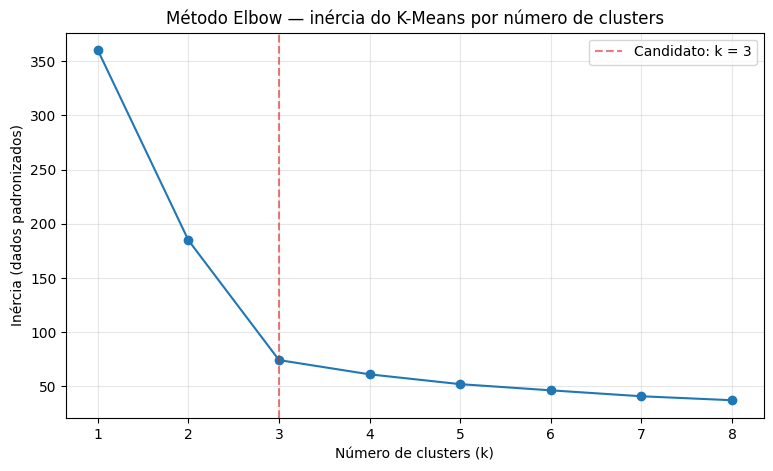

In [5]:
ks = range(1, 9)
distorcoes = []   # lista com a inércia (modelo.inertia_) de cada k

for k in ks:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    modelo.fit(X_padronizado)
    distorcoes.append(modelo.inertia_)

# Tabela com a queda de inércia a cada novo cluster
tabela_elbow = pd.DataFrame({'k': list(ks), 'inercia': distorcoes})
tabela_elbow['queda_absoluta'] = tabela_elbow['inercia'].shift(1) - tabela_elbow['inercia']
tabela_elbow['queda_%'] = tabela_elbow['queda_absoluta'] / tabela_elbow['inercia'].shift(1) * 100
print(tabela_elbow.round(2).to_string(index=False))

# Gráfico Elbow
plt.plot(list(ks), distorcoes, marker='o', color='tab:blue')
plt.axvline(3, color='tab:red', linestyle='--', alpha=0.6, label='Candidato: k = 3')
plt.title('Método Elbow — inércia do K-Means por número de clusters')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inércia (dados padronizados)')
plt.xticks(list(ks))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

**Leitura do Elbow:**

| k | Inércia | Queda em relação ao k anterior |
| ---: | ---: | ---: |
| 1 | 360,00 | — |
| 2 | 184,70 | 175,30 (48,7%) |
| 3 | 74,25 | 110,44 (59,8%) |
| 4 | 61,10 | 13,15 (17,7%) |
| 5 | 52,06 | 9,04 (14,8%) |
| 6 | 46,36 | 5,70 (10,9%) |
| 7 | 40,90 | 5,47 (11,8%) |
| 8 | 37,25 | 3,65 (8,9%) |

**Região candidata: k = 3.** A inércia cai muito de k = 1 para k = 2 (−175,30) e de k = 2 para k = 3 (−110,44, ou seja, 59,8% da inércia que sobrava). A partir de k = 3 a curva muda de comportamento: de k = 3 para k = 4 a queda é de apenas 13,15, cerca de **8 vezes menor** que a queda anterior, e as seguintes continuam pequenas (entre 3,65 e 9,04). É esse "dobra" no gráfico que forma o cotovelo.

Em termos práticos, com 3 clusters a inércia já é **79,4% menor** que com 1 cluster (de 360,00 para 74,25). Acrescentar o 4º, 5º ou 6º grupo traz um ganho adicional pequeno, que não compensa a complexidade de interpretar mais perfis.

Observação: a inércia de k = 1 vale exatamente 360 porque, com 120 unidades e 3 variáveis padronizadas (variância 1), a soma das distâncias ao centro único é 120 × 3. O Elbow indica uma região a investigar; a decisão final será confirmada com o Silhouette Score.

## Apoio: Silhouette Score

Para cada ponto, compara-se a distância média aos demais pontos do seu grupo, $a$, com a menor distância média a outro grupo, $b$:

$$s=\frac{b-a}{\max(a,b)}$$

O **Silhouette Score** é a média dos valores individuais. Para um grupo com um único ponto, adota-se score individual zero.

- Próximo de **1**: grupos compactos e separados segundo as distâncias utilizadas.
- Próximo de **0**: sobreposição ou pontos perto das fronteiras.
- **Negativo**: pontos, em média, mais próximos de outro grupo.

Se $a=2$ e $b=8$, o valor individual é 0,75. Isso **não significa 75% de acertos**: não existe comparação com classes corretas. Não há um limiar universal que valide qualquer agrupamento.

O cálculo exige entre 2 e $n-1$ grupos distintos. Por isso, k = 1 participa do Elbow, mas não da comparação de Silhouette Score. A média pode esconder situações diferentes dentro de cada grupo.


## 5. Comparação por Silhouette Score — 1,5 ponto

Teste **k de 2 a 8**, mantendo `random_state=42` e `n_init=10`. Para cada k, obtenha os rótulos e calcule `silhouette_score(X_padronizado, rotulos)`.

Apresente uma tabela com k e score, além de um gráfico com esses valores. Identifique o maior score do intervalo testado e compare-o com a indicação do Elbow. Se houver divergência, explique-a e justifique sua decisão considerando também a interpretação dos perfis.

Não adicione a coluna de clusters a `X_padronizado` para calcular a métrica. Isso alteraria as distâncias que você pretende avaliar.


 k  silhouette_score
 2            0.4835
 3            0.6031
 4            0.5190
 5            0.4282
 6            0.4343
 7            0.3240
 8            0.3106

Maior Silhouette Score: k = 3 (score = 0.6031)


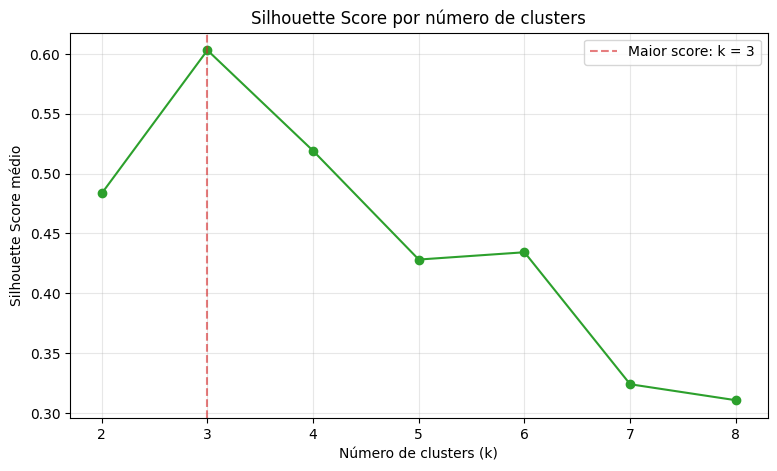

In [6]:
scores = []
ks_sil = range(2, 9)

for k in ks_sil:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    rotulos = modelo.fit_predict(X_padronizado)      # X_padronizado sem coluna de cluster
    scores.append(silhouette_score(X_padronizado, rotulos))

tabela_sil = pd.DataFrame({'k': list(ks_sil), 'silhouette_score': scores})
print(tabela_sil.round(4).to_string(index=False))

melhor_k = tabela_sil.loc[tabela_sil['silhouette_score'].idxmax(), 'k']
print(f"\nMaior Silhouette Score: k = {melhor_k} "
      f"(score = {tabela_sil['silhouette_score'].max():.4f})")

plt.plot(list(ks_sil), scores, marker='o', color='tab:green')
plt.axvline(melhor_k, color='tab:red', linestyle='--', alpha=0.6, label=f'Maior score: k = {melhor_k}')
plt.title('Silhouette Score por número de clusters')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Silhouette Score médio')
plt.xticks(list(ks_sil))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

**Comparação das evidências:**

| k | Silhouette Score |
| ---: | ---: |
| 2 | 0,4835 |
| **3** | **0,6031** |
| 4 | 0,5190 |
| 5 | 0,4282 |
| 6 | 0,4343 |
| 7 | 0,3240 |
| 8 | 0,3106 |

**O maior score do intervalo testado é o de k = 3 (0,6031).** Ele está bem acima do segundo melhor (k = 4, com 0,5190) e do k = 2 (0,4835), e depois de k = 4 os valores caem de forma geral (o pequeno aumento de k = 5 para k = 6 não muda a conclusão, pois ambos ficam em torno de 0,43, muito abaixo de 0,60).

**Comparação com o Elbow.** Não há divergência: o gráfico Elbow indicou k = 3 como cotovelo (a queda de inércia despenca de 110,44 para 13,15 após k = 3) e o Silhouette Score também tem seu pico em k = 3. Duas métricas independentes apontando para o mesmo valor reforçam a escolha.

**Por que não k = 2 nem k = 4?**
- **k = 2** tem inércia muito mais alta (184,70 contra 74,25) e score menor: juntaria perfis diferentes no mesmo grupo.
- **k = 4** apenas divide em dois subgrupos um cluster que já era coerente (veremos que são unidades de ~870 kWh, com 23% a 28% de consumo noturno e demanda de 8,02 kW contra 5,45 kW). O ganho de inércia é pequeno (13,15) e o score cai para 0,5190.

Lembrete: o Silhouette Score **não é porcentagem de acertos**; ele mede o quão compactos e separados os grupos estão segundo as distâncias utilizadas.

## 6. Escolha de k e agrupamento final — 1,0 ponto

Defina `k_escolhido`, ajuste o modelo final sobre `X_padronizado` e crie `df_resultados` como uma cópia de `df`, acrescentando a coluna `cluster`.

Apresente a quantidade de unidades por grupo e o Silhouette Score final. Justifique k com base nas etapas anteriores. Os números dos clusters são apenas identificadores: cluster 2 não é necessariamente maior ou melhor que cluster 0.


In [7]:
k_escolhido = 3

modelo_final = KMeans(n_clusters=k_escolhido, random_state=42, n_init=10)
rotulos_brutos = modelo_final.fit_predict(X_padronizado)

# Os números dos clusters são só identificadores. Para facilitar a leitura,
# renumero em ordem crescente de consumo médio: 0 = menor consumo, 2 = maior consumo.
ordem = (df.assign(r=rotulos_brutos)
           .groupby('r')['consumo_mensal_kwh'].mean()
           .sort_values().index)
mapa = {antigo: novo for novo, antigo in enumerate(ordem)}

df_resultados = df.copy()                       # df original continua intacto
df_resultados['cluster'] = pd.Series(rotulos_brutos).map(mapa).values

print("Unidades por cluster:")
print(df_resultados['cluster'].value_counts().sort_index().to_string())

score_final = silhouette_score(X_padronizado, df_resultados['cluster'])
print(f"\nInércia final (k = {k_escolhido}): {modelo_final.inertia_:.2f}")
print(f"Silhouette Score final: {score_final:.4f}")

# Silhouette médio de cada cluster (mostra a coesão de cada grupo)
sil_individual = silhouette_samples(X_padronizado, df_resultados['cluster'])
print("\nSilhouette médio por cluster:")
print(pd.Series(sil_individual).groupby(df_resultados['cluster']).mean().round(4).to_string())
print("Unidades com silhouette negativo:", int((sil_individual < 0).sum()))

display(df_resultados.head())

Unidades por cluster:
cluster
0    40
1    40
2    40

Inércia final (k = 3): 74.25
Silhouette Score final: 0.6031

Silhouette médio por cluster:
cluster
0    0.7565
1    0.5079
2    0.5449
Unidades com silhouette negativo: 1


,id_unidade,consumo_mensal_kwh,demanda_maxima_kw,consumo_noturno_pct,cluster
0,UC001,791.43,7.28,23.95,1
1,UC002,1349.44,6.65,72.17,2
2,UC003,1355.67,6.50,76.47,2
3,UC004,209.34,0.50,67.76,0
4,UC005,1675.80,5.99,78.53,2


**k escolhido e justificativa:**

**k escolhido = 3.** O modelo final, ajustado sobre `X_padronizado`, resultou em **40 unidades em cada cluster**, inércia de 74,25 e **Silhouette Score de 0,6031**.

Justificativa, em resumo:

1. **Elbow:** a queda de inércia é grande até k = 3 (de 360,00 para 74,25) e depois se torna pequena (13,15 de k = 3 para k = 4).
2. **Silhouette:** k = 3 tem o maior score de todo o intervalo testado (0,6031).
3. **Interpretação:** os três grupos têm perfis claramente diferentes e fáceis de explicar (baixo consumo, consumo médio concentrado de dia, consumo alto concentrado à noite), cada um com uma ação de gestão distinta. Com k = 4 a diferença entre os dois subgrupos extras seria sutil, e com k = 2 perfis distintos ficariam misturados.
4. **Qualidade por grupo:** o Silhouette médio por cluster é 0,76 (cluster 0), 0,51 (cluster 1) e 0,54 (cluster 2), todos positivos. Apenas 1 unidade tem silhouette negativo (valor mínimo de −0,07), ou seja, está próxima da fronteira entre grupos.

Nota sobre a numeração: os identificadores foram reordenados por consumo médio crescente só para facilitar a leitura (0 = menor consumo, 2 = maior). Isso não altera o agrupamento nem as métricas.

## 7. Visualização e interpretação — 2,0 pontos

Construa dois gráficos de dispersão, usando as cores para identificar os clusters:

1. Consumo mensal × demanda máxima.
2. Consumo mensal × percentual de consumo noturno.

Use valores nas unidades originais, títulos, unidades nos eixos e uma legenda que identifique os grupos. Os gráficos mostram projeções em duas dimensões; o modelo utilizou três variáveis.

Crie uma tabela com a quantidade de unidades e as médias das três variáveis por cluster, nas unidades originais. Descreva cada perfil usando esses números e proponha uma ação de gestão de energia para cada um. Diferencie o que os dados mostram do que ainda precisaria ser investigado.

Consumo alto não prova desperdício. Uma recomendação sobre tarifa ou geração solar exigiria dados adicionais de contrato, horários, local e viabilidade.


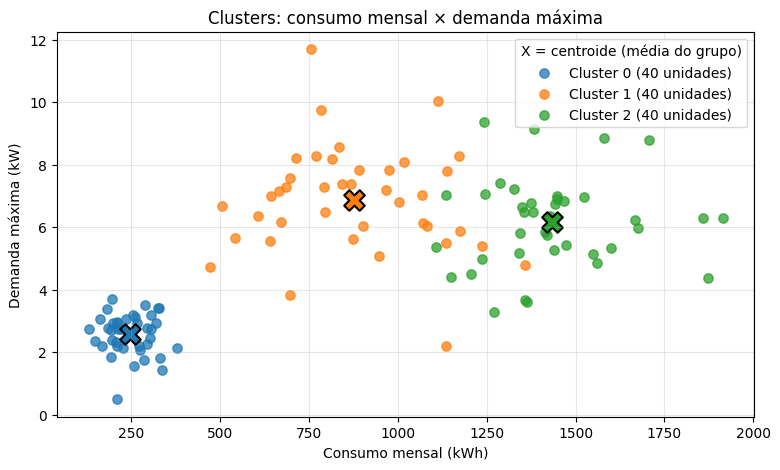

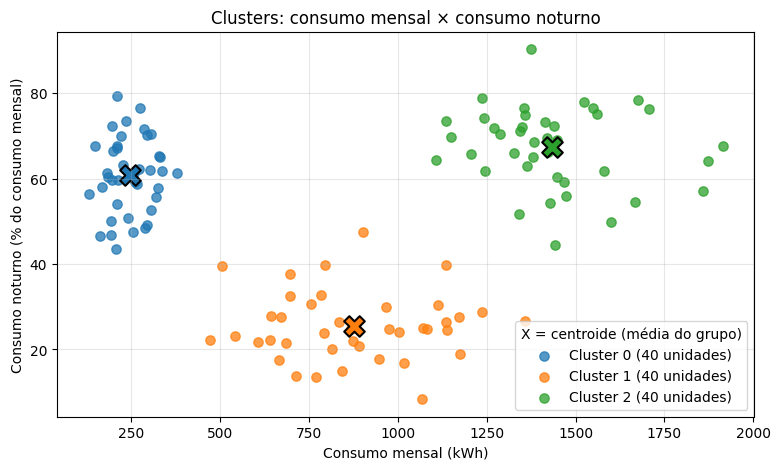

In [8]:
cores = {0: 'tab:blue', 1: 'tab:orange', 2: 'tab:green'}


def dispersao(col_x, col_y, rotulo_x, rotulo_y, titulo):
    plt.figure()
    for c in sorted(df_resultados['cluster'].unique()):
        grupo = df_resultados[df_resultados['cluster'] == c]
        plt.scatter(grupo[col_x], grupo[col_y], s=45, alpha=0.75,
                    color=cores[c], label=f'Cluster {c} ({len(grupo)} unidades)')
        # Centroide em unidades originais (= média do grupo)
        plt.scatter(grupo[col_x].mean(), grupo[col_y].mean(), marker='X', s=220,
                    color=cores[c], edgecolor='black', linewidth=1.5)
    plt.title(titulo)
    plt.xlabel(rotulo_x)
    plt.ylabel(rotulo_y)
    plt.grid(alpha=0.3)
    plt.legend(title='X = centroide (média do grupo)')
    plt.show()


dispersao('consumo_mensal_kwh', 'demanda_maxima_kw',
          'Consumo mensal (kWh)', 'Demanda máxima (kW)',
          'Clusters: consumo mensal × demanda máxima')

dispersao('consumo_mensal_kwh', 'consumo_noturno_pct',
          'Consumo mensal (kWh)', 'Consumo noturno (% do consumo mensal)',
          'Clusters: consumo mensal × consumo noturno')

In [9]:
perfil = df_resultados.groupby('cluster').agg(
    unidades=('id_unidade', 'count'),
    consumo_medio_kwh=('consumo_mensal_kwh', 'mean'),
    demanda_media_kw=('demanda_maxima_kw', 'mean'),
    consumo_noturno_medio_pct=('consumo_noturno_pct', 'mean'),
).round(2)
print("Perfil médio por cluster (unidades originais):")
display(perfil)

# Faixas (mínimo e máximo) para mostrar o quanto cada grupo é homogêneo
faixas = df_resultados.groupby('cluster')[['consumo_mensal_kwh', 'demanda_maxima_kw',
                                           'consumo_noturno_pct']].agg(['min', 'max']).round(2)
print("Faixas (mínimo e máximo) por cluster:")
display(faixas)

# Consumo mensal médio por kW de demanda (razão entre as médias de cada grupo)
razao = (perfil['consumo_medio_kwh'] / perfil['demanda_media_kw']).round(1)
print("kWh consumidos por kW de demanda (razão entre as médias):")
print(razao.to_string())

Perfil médio por cluster (unidades originais):


,unidades,consumo_medio_kwh,demanda_media_kw,consumo_noturno_medio_pct
cluster,,,,
0,40,245.09,2.58,60.82
1,40,876.50,6.87,25.49
2,40,1433.93,6.15,67.37


Faixas (mínimo e máximo) por cluster:


consumo_mensal_kwh          demanda_maxima_kw         \
                       min      max               min    max   
cluster                                                        
0                   130.01   379.07               0.5   3.69   
1                   471.96  1358.74               2.2  11.69   
2                  1108.56  1914.05               3.3   9.36   

        consumo_noturno_pct         
                        min    max  
cluster                             
0                     43.43  79.31  
1                      8.35  47.47  
2                     44.47  90.34

kWh consumidos por kW de demanda (razão entre as médias):
cluster
0     95.0
1    127.6
2    233.2


**Interpretação dos perfis e ações propostas:**

| Cluster | Evidências numéricas e perfil | Ação proposta | Informação adicional necessária |
| --- | --- | --- | --- |
| **0** — Baixo consumo (40 unidades) | Consumo médio de **245,09 kWh** (faixa de 130 a 379 kWh), demanda média de **2,58 kW** e **60,82%** do consumo à noite. É o grupo de menor consumo e de menor demanda, com uso mais voltado ao período noturno. | Acompanhamento leve (baixa prioridade): campanhas de uso consciente e dicas de eficiência (iluminação eficiente, desligar aparelhos em espera). Usar o grupo como referência de consumo baixo. | Tipo de unidade (residencial ou comercial), número de moradores/usuários, lista de equipamentos e tarifa aplicada. |
| **1** — Consumo médio, uso diurno e picos altos (40 unidades) | Consumo médio de **876,50 kWh** (faixa de 472 a 1359 kWh), a **maior demanda média (6,87 kW)** e apenas **25,49%** do consumo à noite, ou seja, uso predominantemente diurno. Consome cerca de 128 kWh por kW de demanda, contra 233 no cluster 2, o que indica picos de potência proporcionalmente mais altos. | Gestão de demanda: escalonar o acionamento de cargas grandes para evitar picos simultâneos e avaliar o contrato de demanda. Por ser consumo diurno, é o grupo mais promissor para estudar geração solar. | Horário exato dos picos (curva de carga de 15 em 15 min), demanda contratada, tipo de atividade, tarifa, área de telhado/local disponível e viabilidade técnica e econômica da geração solar. |
| **2** — Alto consumo concentrado à noite (40 unidades) | Maior consumo médio: **1433,93 kWh** (faixa de 1109 a 1914 kWh), demanda média de **6,15 kW** e **67,37%** do consumo à noite. Alto consumo com uso mais constante ao longo do tempo (≈ 233 kWh por kW de demanda). | Prioridade para auditoria energética: identificar as cargas noturnas contínuas (refrigeração, iluminação, climatização) e avaliar eficiência dos equipamentos e tarifas com diferenciação de horário. | Perfil horário de consumo, equipamentos instalados, tipo de atividade da unidade (consumo alto pode ser necessário), modalidade tarifária e custo por horário. Geração solar sozinha não cobriria o consumo noturno sem armazenamento. |

**O que os dados mostram:** apenas três características por unidade, em um único mês: quanta energia foi consumida, qual foi o pico de potência e que fatia do consumo ocorreu à noite. Com elas, os grupos se separam com clareza (Silhouette 0,6031).

**O que ainda precisaria ser investigado:** os dados **não provam desperdício** nem permitem afirmar quem paga tarifa maior. Consumo alto pode ser perfeitamente justificado pela atividade da unidade. Qualquer recomendação sobre tarifa, geração solar ou armazenamento exige dados adicionais de contrato, curva de carga horária, localização e viabilidade, como indicado na última coluna.

**Sobre os gráficos:** são projeções em duas dimensões de um modelo que usa três variáveis. No gráfico de consumo × demanda os grupos 1 e 2 se sobrepõem em parte, porque diferem principalmente no horário de uso (gráfico de consumo × consumo noturno), onde a separação aparece com nitidez.

## 8. Conclusão — 1,0 ponto

Responda com base nos seus resultados:

1. Como o agrupamento ajuda a equipe de gestão de energia?
2. Por que o menor valor de inércia, isoladamente, não resolve a escolha de k?
3. Por que Silhouette Score não é uma medida de acurácia?
4. Por que é necessário separar as variáveis usadas no modelo da coluna `cluster`?
5. Apresente pelo menos duas limitações: uma sobre a base simulada e outra sobre os dados disponíveis ou o K-Means. Que dados reais você buscaria para aprimorar a análise?

**Conclusão:**

**1. Como o agrupamento ajuda a gestão de energia?** Em vez de analisar 120 unidades uma a uma, a equipe passa a trabalhar com **três perfis**, cada um com características e ações próprias: acompanhamento leve para o baixo consumo (cluster 0), gestão de demanda e estudo de geração solar para o consumo diurno com picos altos (cluster 1) e auditoria energética para o alto consumo noturno (cluster 2). Isso permite priorizar esforços e criar campanhas direcionadas. O agrupamento mostrou, por exemplo, que unidades com consumo total parecido podem se comportar de forma muito diferente em demanda e horário.

**2. Por que o menor valor de inércia não resolve a escolha de k?** Porque a inércia **sempre diminui quando k aumenta**: com k = 120 (um cluster por unidade) ela seria zero, e esse resultado não teria utilidade nenhuma. Nossos resultados mostram isso: a inércia cai de 360,00 (k = 1) até 37,25 (k = 8), mas depois de k = 3 cada cluster novo traz ganho muito pequeno. Por isso olhamos a *variação* da inércia (Elbow), combinada ao Silhouette e à interpretação dos perfis.

**3. Por que o Silhouette Score não é acurácia?** Acurácia compara previsões com respostas corretas conhecidas, e aqui **não existe coluna de classificação correta** (aprendizado não supervisionado). O Silhouette mede apenas a coesão interna dos grupos e a separação entre eles segundo as distâncias. O valor de 0,6031 **não significa 60% de acertos**; significa que, em média, as unidades estão mais próximas do próprio grupo do que dos outros.

**4. Por que separar as variáveis do modelo da coluna `cluster`?** Porque `cluster` é o **resultado** do modelo, não um dado de entrada. Se ela entrasse em `X_padronizado`, o algoritmo e a métrica usariam a própria resposta para calcular distâncias, o que distorceria o agrupamento e inflaria o Silhouette de forma artificial (vazamento de informação). Pelo mesmo motivo `id_unidade`, que é só um identificador, fica fora do modelo.

**5. Limitações e dados reais.**
- **Base simulada:** os 120 registros são fictícios, gerados com NumPy (semente 303), e não vêm de medidores reais. Os três grupos nítidos podem refletir a forma como os dados foram gerados e podem não aparecer com a mesma clareza em dados reais, que costumam ter mais ruído e perfis misturados.
- **Dados disponíveis:** há só um mês de referência e três variáveis. Não há tipo de unidade, tarifa, localização, sazonalidade nem curva de carga, e por isso não é possível afirmar desperdício nem recomendar tarifa ou solar com segurança.
- **K-Means:** exige definir k antes, assume grupos mais ou menos esféricos e de tamanho parecido, é sensível a escala e a valores atípicos e depende da inicialização (por isso usamos `random_state=42` e `n_init=10`). Há ainda 1 unidade com silhouette negativo, na fronteira entre grupos, e cada unidade é obrigada a pertencer a um único grupo.

**Dados reais que buscaria:** curva de carga de 15 em 15 minutos (medidores inteligentes) por pelo menos 12 meses, para captar sazonalidade; classe e tipo da unidade (residencial, comercial, industrial); modalidade tarifária e demanda contratada; localização e dados climáticos; área construída, número de usuários e lista de equipamentos; e, se houver, dados de geração própria.

## Entrega e critérios de avaliação

Entregue o **notebook `.ipynb` preenchido e executado**, contendo identificação, códigos, tabelas, gráficos, justificativas e conclusões. A base está incorporada; não é necessário um arquivo externo para executar a atividade. Prazo e canal de entrega serão definidos pelo professor.

| Critério | Pontos |
| --- | ---: |
| Exploração e compreensão dos dados | 1,0 |
| Seleção das variáveis e padronização justificada | 1,5 |
| Elbow: implementação, gráfico e leitura | 1,5 |
| Silhouette Score: comparação, gráfico e interpretação | 1,5 |
| Modelo final e justificativa de k | 1,0 |
| Visualizações, perfis e ações fundamentadas | 2,0 |
| Conclusões e limitações | 1,0 |
| **Total** | **10,0** |

A avaliação considera a correção do código e a capacidade de explicar as escolhas e interpretar os resultados. Não há pontuação por apenas escolher um k específico sem justificativa.

### Antes de entregar

- Preencha nome(s), RM(s) e turma.
- Reinicie o ambiente e execute as células na ordem.
- Confira se as tabelas e os gráficos permanecem salvos no notebook.
- Verifique se usou as três variáveis e excluiu identificador e rótulos do cálculo das distâncias.
- Substitua os espaços de resposta por suas análises.

### Documentação de apoio

- [K-Means e inércia — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)
- [Silhouette Score — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)
- [StandardScaler — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

Atividade inspirada na sequência do notebook de referência fornecido pelo professor, com nova base de energia e cuidados adicionais na seleção e avaliação das variáveis.
